In [105]:
import pandas as pd
from scipy.fftpack import dct, idct
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import tqdm
import time

**Wczytnie danych**

In [91]:
df = pd.read_csv("wraki.csv", names=["x", "y", "z"], sep='\s+')
df

,x,y,z
0,452606.36,5967748.7,NaN
1,452606.41,5967748.7,NaN
2,452606.46,5967748.7,NaN
3,452606.51,5967748.7,NaN
4,452606.56,5967748.7,NaN
...,...,...,...
714570,452631.36,5967819.4,NaN
714571,452631.41,5967819.4,NaN
714572,452631.46,5967819.4,NaN
714573,452631.51,5967819.4,NaN


**Pobranie informacji od użytkowniak**

In [116]:
size_block = int(input("Block size: "))
acc = float(input("Accuracy: "))
to_zip = input("To zip?[Y/N]: ")
to_zip = False if to_zip =='N' else True

Block size: 20
Accuracy: 0.05
To zip?[Y/N]: Y


**Kompresja danych**

In [117]:
def compress_bathymatic_data(grid, size_block, padding_h, padding_w, coords):
    h, w = grid.shape
    if h % size_block != 0:
        padding_h_zeros = np.zeros((h, padding_h))
        padding_h_zeros[:] = np.nan
        grid = np.hstack([grid, padding_h_zeros])
    if w % size_block != 0:
        padding_w_zeros = np.zeros((padding_w, w + padding_h))
        padding_w_zeros[:] = np.nan
        grid = np.vstack([grid, padding_w_zeros])
    h, w = grid.shape
    compression = np.zeros(grid.shape, dtype='float32')
    grid_ar = np.array(grid)
    for i in tqdm.tqdm(range(0, h, size_block), desc=coords):
        for j in range(0, w, size_block):
            compression[i:i+size_block, j:j+size_block] = dct(grid_ar[i:i+size_block, j:j+size_block], norm='ortho')
    return compression

**Dekompresja danych**

In [118]:
def decompress_bathymatic_data(compressed, size_block, padding_h, padding_w, coords):
    decompression = np.zeros(compressed.shape, dtype='float32')
    h, w = compressed.shape
    for i in tqdm.tqdm(range(0, h, size_block), desc=coords):
        for j in range(0, w, size_block):
            decompression[i:i + size_block, j:j + size_block] = idct(compressed[i:i + size_block, j:j + size_block], norm='ortho')
    if padding_h != 0 and padding_w != 0:
        decompression_new = decompression[:-padding_w, :-padding_h]
    elif padding_h != 0 and padding_w == 0:
        decompression_new = decompression[:-padding_w, :]
    elif padding_h == 0 and padding_w != 0:
        decompression_new = decompression[:, :-padding_h]
    else:
        decompression_new = decompression[:, :]
    return decompression_new

**Funckja do wyznaczania siatki, po której będzie interować**

In [111]:
def get_meshgrids(data):
    x_min = np.min(data[:, 0])
    x_max = np.max(np.round(data[:, 0], 2))
    step = data[:, 0][1] - data[:, 0][0]
    y_min = np.min(data[:, 1])
    y_max = np.max(np.round(data[:, 1], 2))
    x_lim = (x_min, x_max, step)
    y_lim = (y_min, y_max, step)
    xx, yy = np.meshgrid(np.arange(x_lim[0], x_lim[1], x_lim[2]), np.arange(y_lim[0], y_lim[1], y_lim[2]))
    zz = np.reshape(data[:, 2], yy.shape)
    return xx, yy, zz

**Wykonanie kompresji**

In [119]:
data = df.to_numpy()
xx, yy, zz = get_meshgrids(data)

start = time.time()

spacing_h_x = size_block - (xx.shape[0] % size_block)
spacing_w_x = size_block - (xx.shape[1] % size_block)
xx_comp = compress_bathymatic_data(xx, size_block, spacing_h_x, spacing_w_x, 'X compression')
spacing_h_y = size_block - (yy.shape[0] % size_block)
spacing_w_y = size_block - (yy.shape[1] % size_block)
yy_comp = compress_bathymatic_data(yy, size_block, spacing_h_y, spacing_w_y, 'Y compression')
spacing_h_z = size_block - (zz.shape[0] % size_block)
spacing_w_z = size_block - (zz.shape[1] % size_block)
zz_comp = compress_bathymatic_data(zz, size_block, spacing_h_z, spacing_w_z, 'Z compression')
zz_comp

end = time.time()
print(end - start)

Z compression: 100%|██████████| 72/72 [00:00<00:00, 3055.12it/s]

0.09425592422485352


**Wykonanie dekompresji danych**

In [120]:
start = time.time()

xx_decomp = decompress_bathymatic_data(xx_comp, size_block, spacing_h_x, spacing_w_x, 'X decompression')
yy_decomp = decompress_bathymatic_data(yy_comp, size_block, spacing_h_y, spacing_w_y, 'Y decompression')
zz_decomp = decompress_bathymatic_data(zz_comp, size_block, spacing_h_z, spacing_w_z, 'Z decompression')

end = time.time()
print(end - start)

# z_abs = abs(zz - zz_decomp)
df_kom = pd.DataFrame({'x': xx_comp.flatten(), 'y': yy_comp.flatten(), 'z': zz_comp.flatten()})
df_kom

Z decompression: 100%|██████████| 72/72 [00:00<00:00, 3129.10it/s]

0.09736156463623047


,x,y,z
0,2.024119e+06,26688584.0,NaN
1,-1.280302e+00,0.0,NaN
2,0.000000e+00,0.0,NaN
3,-1.410591e-01,0.0,NaN
4,0.000000e+00,0.0,NaN
...,...,...,...
729295,NaN,NaN,NaN
729296,NaN,NaN,NaN
729297,NaN,NaN,NaN
729298,NaN,NaN,NaN


**Zapis do pliku zip**

In [122]:
if to_zip:
    df_kom.to_csv('wraki_out.csv.gz', compression='gzip', sep=' ', header=False, index=False)
    cr_value = Path('wraki_utm_lab1.csv').stat().st_size / Path('wraki_out.csv.gz').stat().st_size
    print(f'Współczynnik kompresji: {cr_value}')
else:
    df_kom.to_csv('wraki_out.csv.gz', sep=' ', header=False, index=False)
    cr_value = Path('wraki_utm_lab1.csv').stat().st_size / Path('wraki_out.csv').stat().st_size
    print(f'Współczynnik kompresji: {cr_value}')

Współczynnik kompresji: 25.60787520846469


**Wyświetlenie wyników**

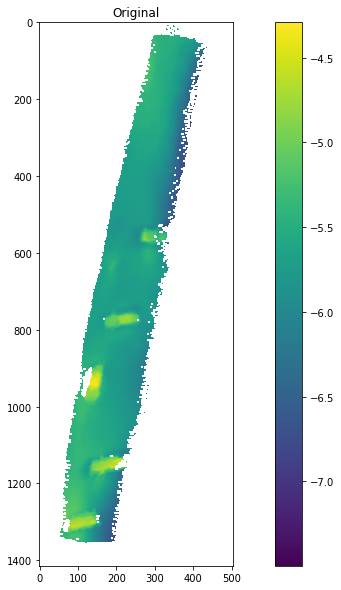

In [121]:
plt.rcParams['figure.figsize'] = [15, 10]
plt.figure()
plt.title('Original')
p = plt.imshow(zz)
plt.colorbar(p)

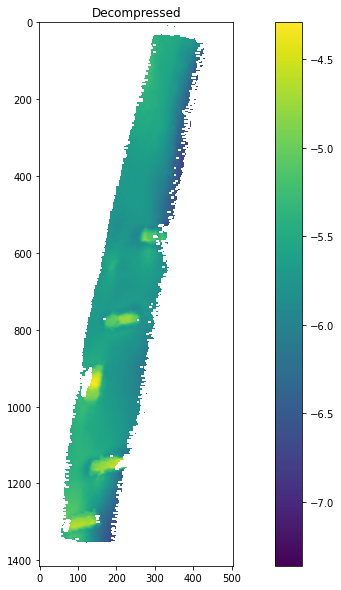

In [102]:
plt.figure()
plt.title('Decompressed')
p = plt.imshow(zz_decomp)
plt.colorbar(p)

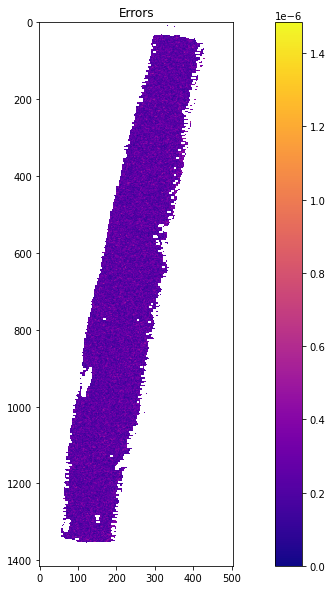

In [103]:
z_abs = abs(zz - zz_decomp)
plt.figure()
plt.title('Errors')
p = plt.imshow(z_abs, cmap='plasma')
plt.colorbar(p)